In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the processed customer dataset
df = pd.read_parquet("../output/perfectpetclub_churn_features.parquet")

# Check the dataset
print("Total customers:", len(df))
print("Total columns:", len(df.columns))
print("Columns:", df.columns.tolist())

df.head()

Total customers: 221
Total columns: 20
Columns: ['customer_id', 'email', 'county', 'sub_start_date', 'sub_end_date', 'auto_renew', 'subscription_tier', 'delivery_service', 'is_churned', 'subscription_tenure_days', 'postcode_district', 'total_orders', 'total_spend_gbp', 'avg_order_value_gbp', 'most_recent_order_date', 'primary_payment_gateway', 'total_reviews_written', 'avg_star_rating', 'one_star_reviews_count', 'five_star_reviews_count']


,customer_id,email,county,sub_start_date,sub_end_date,auto_renew,subscription_tier,delivery_service,is_churned,subscription_tenure_days,postcode_district,total_orders,total_spend_gbp,avg_order_value_gbp,most_recent_order_date,primary_payment_gateway,total_reviews_written,avg_star_rating,one_star_reviews_count,five_star_reviews_count
0,1,Sargsyan701@somemail.co.uk,Berkshire,2026-01-01 00:00:00.000,2026-01-31 00:00:00.000,0,SuperSaver,Economy72,1,30,SL6,20,744.55,37.23,2026-01-10 20:43:36.234,paypool,10,2.40,4,1
1,2,Mammadova282@example.com,Oxfordshire,2026-01-01 00:00:00.000,2026-11-27 00:00:00.000,1,SuperSaver,Economy72,0,330,OX7,253,10369.61,40.99,2026-11-09 21:35:20.498,cardpay,113,3.18,19,27
2,3,Sana858@notrealemail.com,Worcestershire,2026-01-01 00:00:00.000,2026-11-27 00:00:00.000,1,Premium,SignedFor24,0,330,DY10,304,12846.92,42.26,2026-11-07 21:31:22.450,directdebit,134,3.08,28,31
3,4,Omar.Farooq4@example.com,Kent,2026-01-01 00:00:00.000,2026-11-27 00:00:00.000,1,Premium,SignedFor24,0,330,TN9,1055,95775.04,90.78,2026-11-09 21:56:40.499,paypool,537,3.30,83,144
4,5,Alejandro357@somemail.co.uk,Hertfordshire,2026-01-01 00:00:00.000,2026-05-01 00:00:00.000,0,SuperSaver,Economy72,1,120,WD7,44,1797.38,40.85,2026-04-12 19:52:46.436,cardpay,18,3.56,1,5


## Customer Retention Overview

This chart shows the percentage of customers who have enabled or disabled subscription auto renewal. Customers who have disabled auto renewal are classified as churned for this analysis.

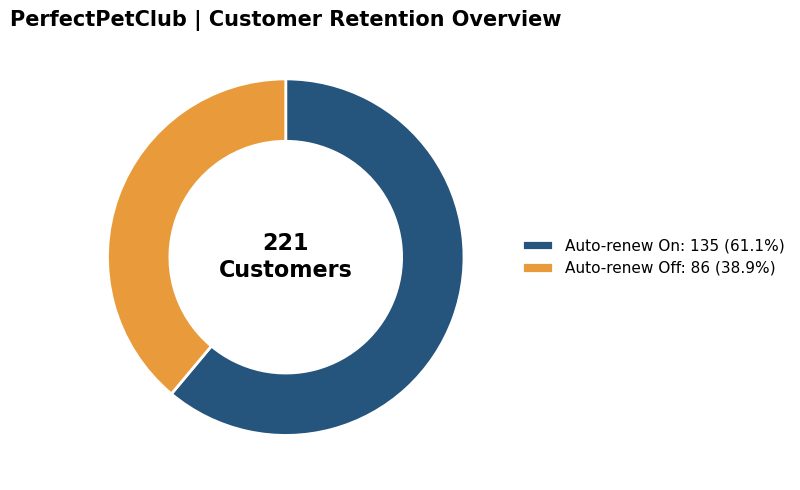

In [6]:


churn_counts = df["is_churned"].value_counts().reindex([0, 1], fill_value=0)
total = churn_counts.sum()

fig, ax = plt.subplots(figsize=(9, 5))

colors = ["#25547C", "#E99B3C"]

wedges, _ = ax.pie(
    churn_counts,
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={"width": 0.35, "edgecolor": "white", "linewidth": 2}
)


ax.text(
    0, 0, f"{total}\nCustomers",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)


labels = [
    f"Auto-renew On: {churn_counts[0]} ({churn_counts[0]/total:.1%})",
    f"Auto-renew Off: {churn_counts[1]} ({churn_counts[1]/total:.1%})"
]

ax.legend(
    wedges,
    labels,
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
    fontsize=11
)

ax.set_title(
    "PerfectPetClub | Customer Retention Overview",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()


fig.savefig(
    "../output/customer_churn_overview.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()